In [1]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import numpy as np
import pandas as pd
import seaborn as sns

# do not change these, they are set up for current directory structure and pre-calculated density profiles
paths = {
    'Pristine': './data/pristine/',
    'NaOCl': './data/chlorinated/',
    'NaOCl + NaOH': './data/chlorinated_alkaline/'
}

membrane_bounds = { # as determined by the intersection of the polymer and water density profiles
    'Pristine': np.array([ 26.50190379,  49.39451567,  72.28712755,  95.17973943,   118.07235131]),
    'NaOCl': np.array([ 24.32690572,  47.28358504,  70.24026436,  93.19694368,   116.153623  ]),
    'NaOCl + NaOH': np.array([ 5.21002256, 28.0388828 , 50.86774304, 73.69660328, 96.52546351])
}

main_fig_output_path = './main_figures/'
si_fig_output_path = './si_figures/'

In [2]:
# change these to match the experimental data and formatting requirements
color_map = {
    'Pristine' : '#D55E00',
    'NaOCl' : '#0173B2',
    'NaOCl + NaOH' : "#CC78BC"
}

labels = [
    'Pristine',
    'NaOCl',
    'NaOCl + NaOH'
]

plt.rcParams['font.size'] = 12
col_width = 4  # inches
row_height = 4
dpi = 300 # for output PNG

## Hydrogen bonds

### Polymer-polymer (N-H..O)

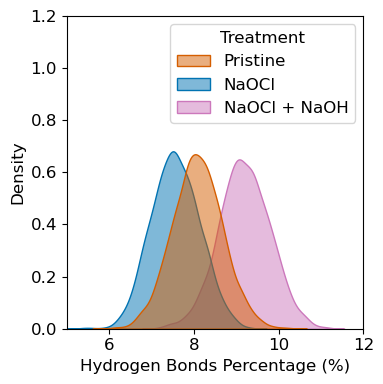

In [6]:
hbonds = pd.DataFrame()
for label in labels:
    path = paths[label]
    tmp = pd.read_csv(path + 'hbonds_polymer-polymer.csv')
    tmp['Treatment'] = label
    hbonds = pd.concat([hbonds, tmp], ignore_index=True)

# plot the KDE
fig, ax = plt.subplots(figsize=(col_width, row_height))
sns.kdeplot(data=hbonds, x='hbonds_percentage', hue='Treatment', fill=True, alpha=0.5, ax=ax, palette=color_map, common_norm=False)
ax.set_xlabel('Hydrogen Bonds Percentage (%)')
ax.set_ylabel('Density')
ax.set_xlim(5,12)
ax.set_ylim(0,1.2)
plt.tight_layout()
fig.savefig(main_fig_output_path + 'hbonds_percent_polymer-polymer_kde.png', dpi=dpi, bbox_inches='tight')
fig.savefig(main_fig_output_path + 'hbonds_percent_polymer-polymer_kde.pdf', bbox_inches='tight')


### Polymer-water (N-H..O)

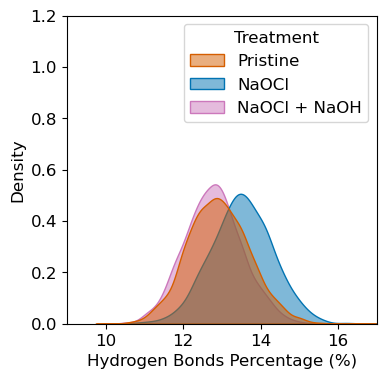

In [7]:
hbonds = pd.DataFrame()
for label in labels:
    path = paths[label]
    tmp = pd.read_csv(path + 'hbonds_polymer-water.csv')
    tmp['Treatment'] = label
    hbonds = pd.concat([hbonds, tmp], ignore_index=True)

fig, ax = plt.subplots(figsize=(col_width, row_height))
sns.kdeplot(data=hbonds, x='hbonds_percentage', hue='Treatment', fill=True, alpha=0.5, ax=ax, palette=color_map, common_norm=False)
ax.set_xlabel('Hydrogen Bonds Percentage (%)')
ax.set_ylabel('Density')
ax.set_xlim(9,17)
ax.set_ylim(0,1.2)
fig.savefig(si_fig_output_path + 'hbonds_percent_polymer-water_kde.png', dpi=dpi, bbox_inches='tight')
fig.savefig(si_fig_output_path + 'hbonds_percent_polymer-water_kde.pdf', bbox_inches='tight')

### Water-polymer (O-H..O)

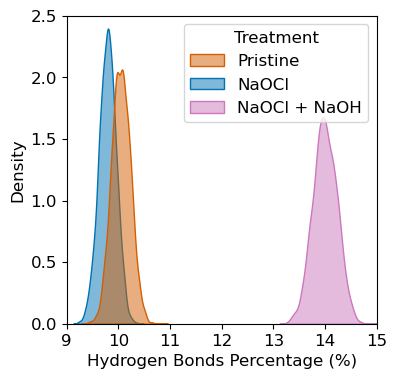

In [8]:
hbonds = pd.DataFrame()
for label in labels:
    path = paths[label]
    tmp = pd.read_csv(path + 'hbonds_water-polymer.csv')
    tmp['Treatment'] = label
    hbonds = pd.concat([hbonds, tmp], ignore_index=True)

fig, ax = plt.subplots(figsize=(col_width, row_height))
sns.kdeplot(data=hbonds, x='hbonds_percentage', hue='Treatment', fill=True, alpha=0.5, ax=ax, palette=color_map, common_norm=False)
ax.set_xlabel('Hydrogen Bonds Percentage (%)')
ax.set_ylabel('Density')
ax.set_xlim(9,15)
ax.set_ylim(0,2.5)
fig.savefig(si_fig_output_path + 'hbonds_percent_water-polymer_kde.png', dpi=dpi, bbox_inches='tight')
fig.savefig(si_fig_output_path + 'hbonds_percent_water-polymer_kde.pdf', bbox_inches='tight')

## MSD

In [3]:
import statsmodels.api as sm
from typing import Optional, Tuple

def fit_msd(msds: np.ndarray, lagtimes: np.ndarray, start_idx: Optional[int] = None, end_idx: Optional[int] = None, dimensionality: int = 3) -> Tuple[float, float]:
        '''
        Fit the MSD vs time lags to a line to extract the diffusion coefficient.

        Parameters
        ----------
        msds : np.array
            Mean squared displacement over the time lags for the linear fit (nm^2)
        lagtimes : np.array
            Time lags corresponding to the MSD values for the linear fit (ns)
        start_idx : int
            Starting index for the region to fit the MSD, default=None means start at 10% of the time lags,
            which is the same as Gromacs gmx msd defaults
        end_idx : int
            Ending index for the region to fit the MSD, default=None means end at 90% of the time lags,
            which is the same as Gromacs gmx msd defaults
        dimensionality : int
            Dimensionality of the system, default=3

        Returns
        -------
        D : float
            Diffusion coefficient for the calculated MSD (nm^2 / ns = D*1e-9 m^2 / s)
        stderr : float
            Standard error for D in the linear fit

        '''

        # get the region of the MSD to fit
        if start_idx is None:
            val = np.quantile(lagtimes, 0.1)
            start_idx = np.where(lagtimes >= val)[0][0]
        if end_idx is None:
            val = np.quantile(lagtimes, 0.9)
            end_idx = np.where(lagtimes <= val)[0][-1]

        # set up the matrices for the linear regression
        X = lagtimes[start_idx:end_idx]
        Y = msds[start_idx:end_idx]
        X = sm.add_constant(X)

        # fit the ordinary least squares model and get the slope
        ols = sm.OLS(Y, X)
        fit_results = ols.fit()
        b, m = fit_results.params
        be, me = fit_results.bse # standard error in parameters

        # The slope `m` has units nm^2 / ns per ns => nm^2 / ns^1, MSD slope -> 2*d*D
        D = m / 2.0 / dimensionality
        stderr = me / 2.0 / dimensionality

        return D, stderr # nm^2 / ns = 1e-9 m^2 / s

### Water

/Users/nate_schwindt/anaconda3/envs/mda/lib/python3.10/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)
/Users/nate_schwindt/anaconda3/envs/mda/lib/python3.10/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)
/Users/nate_schwindt/anaconda3/envs/mda/lib/python3.10/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


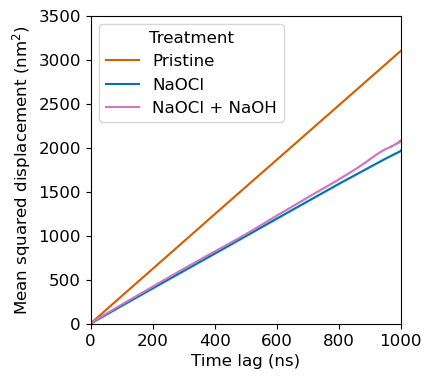

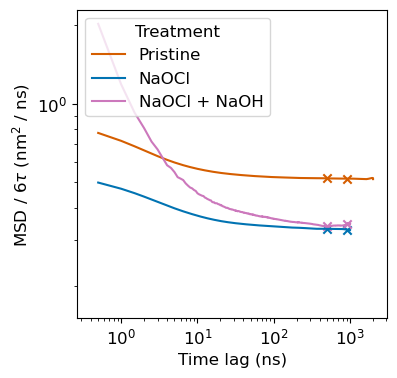

In [19]:
start_time = 500 # ns
end_time = 900 # ns

# plot MSDs
fig1, ax1 = plt.subplots(figsize=(col_width, row_height))
for label in labels:
    path = paths[label]    
    msds = pd.read_csv(path + 'water_msd_unrestricted.csv')
    ax1.plot(msds['time'], msds['msd'], label=label, color=color_map[label])
    ax1.fill_between(msds['time'], msds['lower_ci'], msds['upper_ci'], alpha=0.2, color=color_map[label])

ax1.set_xlabel('Time lag (ns)')
ax1.set_ylabel('Mean squared displacement (nm$^2$)')
ax1.set_xlim(0,1000)
ax1.set_ylim(0,3500)
ax1.legend(title='Treatment', loc='upper left')

# plot MSDs, loglog
fig2, ax2 = plt.subplots(figsize=(col_width, row_height))
for path, label in zip(paths, labels):
    path = paths[label]  
    msds = pd.read_csv(path + 'water_msd_unrestricted.csv')
    ax2.loglog(msds['time'], msds['msd'] / (6*msds['time']), label=label, color=color_map[label])
    ax2.fill_between(np.log(msds['time']), np.log(msds['lower_ci'] / (6*msds['time'])), np.log(msds['upper_ci'] / (6*msds['time'])), alpha=0.2, color=color_map[label])

    start_idx = np.where(msds['time'] >= start_time)[0][0]
    end_idx = np.where(msds['time'] <= end_time)[0][-1]
    ax2.scatter(msds['time'][[start_idx, end_idx]], msds['msd'][[start_idx, end_idx]] / (6*msds['time'][[start_idx, end_idx]]), color=color_map[label], marker='x')

ax2.set_xlabel('Time lag (ns)')
ax2.set_ylabel(r'MSD / 6$\tau$ (nm$^2$ / ns) ')
ax2.legend(title='Treatment', loc='upper left')

In [ ]:
import statsmodels.api as sm

def fit_msd(msds: np.ndarray, lagtimes: np.ndarray):
    '''
    Fit the MSD vs time lags to a line to extract the diffusion coefficient.

    Parameters
    ----------
    msds : np.array
        Mean squared displacement over the time lags for the linear fit (nm^2)
    lagtimes : np.array
        Time lags corresponding to the MSD values for the linear fit (ns)
    '''

    X = lagtimes
    X = sm.add_constant(X)
    Y = msds

    # Perform a linear fit of the MSD vs. lag time
    ols = sm.OLS(Y, X)
    fit_results = ols.fit()
    b,m = fit_results.params
    be,me = fit_results.bse # standard error in parameters

    # The diffusion coefficient is the slope divided by the dimensionality
    D = m / 6.0  # For 3D diffusion, divide by 6
    stderr = me / 6.0  # Standard error in the slope divided by 6

    return D, stderr

: 

/var/folders/c7/911byk5d5jl0vp7m92bxn01w0000gn/T/ipykernel_28520/2472247106.py:24: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  diffusion_coefficients = pd.concat([diffusion_coefficients, tmp], ignore_index=True)
/var/folders/c7/911byk5d5jl0vp7m92bxn01w0000gn/T/ipykernel_28520/2472247106.py:88: UserWarning: Attempt to set non-positive xlim on a log-scaled axis will be ignored.
  ax2.set_xlim(0,1000)


,Treatment,Region,D,stderr
0,Pristine,Middle,0.004660,0.000015
1,Pristine,All,0.009278,0.000013
2,Pristine,Interface,0.009566,0.000012
3,NaOCl,Middle,0.003968,0.000013
4,NaOCl,All,0.006151,0.000010
5,NaOCl,Interface,0.006119,0.000007
6,NaOCl + NaOH,Middle,0.004192,0.000005
7,NaOCl + NaOH,All,0.006287,0.000011
8,NaOCl + NaOH,Interface,0.006617,0.000013


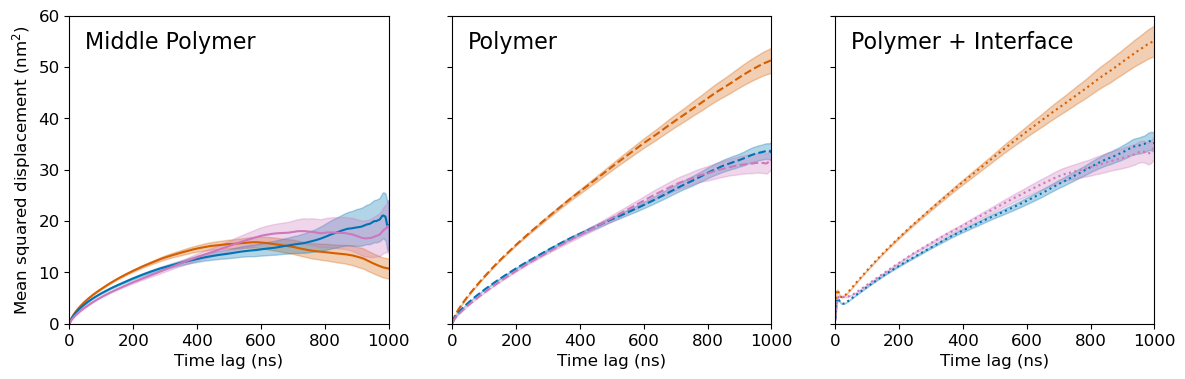

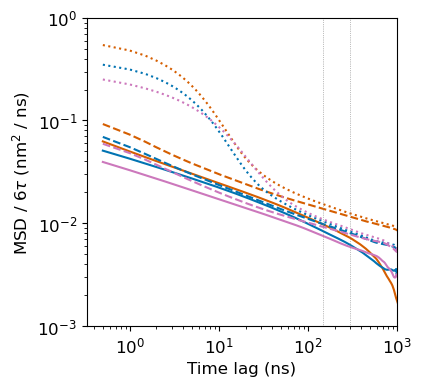

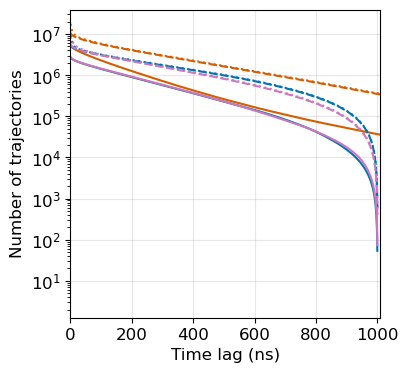

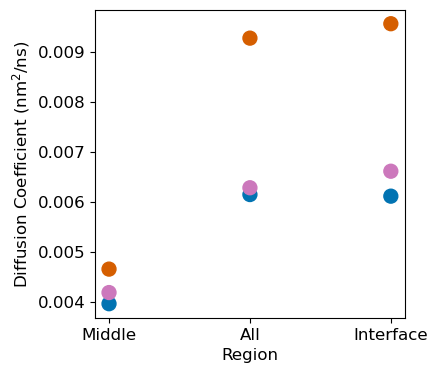

In [23]:
start_time = 150 # ns
end_time = 300 # ns

diffusion_coefficients = pd.DataFrame(columns=['Treatment', 'Region', 'D', 'stderr'])

# plot MSDs
fig1, ax1 = plt.subplots(1,3, figsize=(3.5*col_width, row_height), sharey=True)
for label in labels:
    path = paths[label]

    msds = pd.read_csv(path + 'msd_middle_membrane.csv')
    ax1[0].plot(msds['Tau_ps'] / 1000, msds['MSD_A2'] / 10**2, label=label, color=color_map[label], ls='-')
    ax1[0].fill_between(msds['Tau_ps'] / 1000, (msds['MSD_A2'] / 10**2) - (msds['MSD_std_A2'] / 10**2), (msds['MSD_A2'] / 10**2) + (msds['MSD_std_A2'] / 10**2), color=color_map[label], alpha=0.3)

    start_idx = np.where(msds['Tau_ps'] / 1000 >= start_time)[0][0]
    end_idx = np.where(msds['Tau_ps'] / 1000 <= end_time)[0][-1]
    D, stderr = fit_msd(msds['MSD_A2'].values[start_idx:end_idx] / 10**2, msds['Tau_ps'].values[start_idx:end_idx] / 1000)
    tmp = pd.DataFrame({
        'Treatment': label,
        'Region': 'Middle',
        'D': D,
        'stderr': stderr
    }, index=[0])
    diffusion_coefficients = pd.concat([diffusion_coefficients, tmp], ignore_index=True)

    msds = pd.read_csv(path + 'msd_all_membrane.csv')
    ax1[1].plot(msds['Tau_ps'] / 1000, msds['MSD_A2'] / 10**2, label=label, color=color_map[label], ls='--')
    ax1[1].fill_between(msds['Tau_ps'] / 1000, (msds['MSD_A2'] / 10**2) - (msds['MSD_std_A2'] / 10**2), (msds['MSD_A2'] / 10**2) + (msds['MSD_std_A2'] / 10**2), color=color_map[label], alpha=0.3)

    start_idx = np.where(msds['Tau_ps'] / 1000 >= start_time)[0][0]
    end_idx = np.where(msds['Tau_ps'] / 1000 <= end_time)[0][-1]
    D, stderr = fit_msd(msds['MSD_A2'].values[start_idx:end_idx] / 10**2, msds['Tau_ps'].values[start_idx:end_idx] / 1000)
    tmp = pd.DataFrame({
        'Treatment': label,
        'Region': 'All',
        'D': D,
        'stderr': stderr
    }, index=[0])
    diffusion_coefficients = pd.concat([diffusion_coefficients, tmp], ignore_index=True)

    msds = pd.read_csv(path + 'msd_interface_membrane.csv')
    ax1[2].plot(msds['Tau_ps'] / 1000, msds['MSD_A2'] / 10**2, label=label, color=color_map[label], ls=':')
    ax1[2].fill_between(msds['Tau_ps'] / 1000, (msds['MSD_A2'] / 10**2) - (msds['MSD_std_A2'] / 10**2), (msds['MSD_A2'] / 10**2) + (msds['MSD_std_A2'] / 10**2), color=color_map[label], alpha=0.3)

    start_idx = np.where(msds['Tau_ps'] / 1000 >= start_time)[0][0]
    end_idx = np.where(msds['Tau_ps'] / 1000 <= end_time)[0][-1]
    D, stderr = fit_msd(msds['MSD_A2'].values[start_idx:end_idx] / 10**2, msds['Tau_ps'].values[start_idx:end_idx] / 1000)
    tmp = pd.DataFrame({
        'Treatment': label,
        'Region': 'Interface',
        'D': D,
        'stderr': stderr
    }, index=[0])
    diffusion_coefficients = pd.concat([diffusion_coefficients, tmp], ignore_index=True)

tmp = ["Middle Polymer", "Polymer", "Polymer + Interface"]
for i in range(3):
    ax1[i].set_xlabel('Time lag (ns)')
    ax1[i].set_xlim(0,1000)
    ax1[i].set_ylim(0,60)
    ax1[i].text(0.05, 0.95, tmp[i], transform=ax1[i].transAxes, ha='left', va='top', fontsize=16)

ax1[0].set_ylabel('Mean squared displacement (nm$^2$)')

# plot MSDs, loglog
fig2, ax2 = plt.subplots(figsize=(col_width, row_height))
for path, label in zip(paths, labels):
    path = paths[label]  
    # middle
    msds = pd.read_csv(path + 'msd_middle_membrane.csv')
    ax2.loglog(msds['Tau_ps'] / 1000, msds['MSD_A2'] / (6*msds['Tau_ps'] / 1000) / 10**2, label=label, color=color_map[label], ls='-')

    # all
    msds = pd.read_csv(path + 'msd_all_membrane.csv')
    ax2.loglog(msds['Tau_ps'] / 1000, msds['MSD_A2'] / (6*msds['Tau_ps'] / 1000) / 10**2, label=label, color=color_map[label], ls='--')

    # interface
    msds = pd.read_csv(path + 'msd_interface_membrane.csv')
    ax2.loglog(msds['Tau_ps'] / 1000, msds['MSD_A2'] / (6*msds['Tau_ps'] / 1000) / 10**2, label=label, color=color_map[label], ls=':')

start_idx = np.where(msds['Tau_ps'] / 1000 >= start_time)[0][0]
end_idx = np.where(msds['Tau_ps'] / 1000 <= end_time)[0][-1]
ax2.axvline(msds['Tau_ps'][start_idx] / 1000, color='gray', ls=':', lw=0.5)
ax2.axvline(msds['Tau_ps'][end_idx] / 1000, color='gray', ls=':', lw=0.5)

ax2.set_xlabel('Time lag (ns)')
ax2.set_ylabel(r'MSD / 6$\tau$ (nm$^2$ / ns) ')
ax2.set_xlim(0,1000)
ax2.set_ylim(10**-3, 10**0)

# plot number of trajectories
fig3, ax3 = plt.subplots(figsize=(col_width, row_height))
for label in labels:
    path = paths[label]    

    msds = pd.read_csv(path + 'msd_middle_membrane.csv')
    ax3.plot(msds['Tau_ps'] / 1000, msds['Samples'], label=label, color=color_map[label], ls='-')

    msds = pd.read_csv(path + 'msd_all_membrane.csv')
    ax3.plot(msds['Tau_ps'] / 1000, msds['Samples'], label=label, color=color_map[label], ls='--')

    msds = pd.read_csv(path + 'msd_interface_membrane.csv')
    ax3.plot(msds['Tau_ps'] / 1000, msds['Samples'], label=label, color=color_map[label], ls=':')

ax3.set_xlabel('Time lag (ns)')
ax3.set_ylabel('Number of trajectories')
ax3.set_xlim(0,1010)
ax3.set_yscale('log')
ax3.grid(alpha=0.3)

fig4, ax4 = plt.subplots(figsize=(col_width, row_height))
ax4.scatter(diffusion_coefficients['Region'], diffusion_coefficients['D'], color=[color_map[t] for t in diffusion_coefficients['Treatment']], s=100)
ax4.set_xlabel('Region')
ax4.set_ylabel('Diffusion Coefficient (nm$^2$/ns)')

diffusion_coefficients

### Ions (Na+)

/Users/nate_schwindt/anaconda3/envs/mda/lib/python3.10/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)
/Users/nate_schwindt/anaconda3/envs/mda/lib/python3.10/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)
/Users/nate_schwindt/anaconda3/envs/mda/lib/python3.10/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


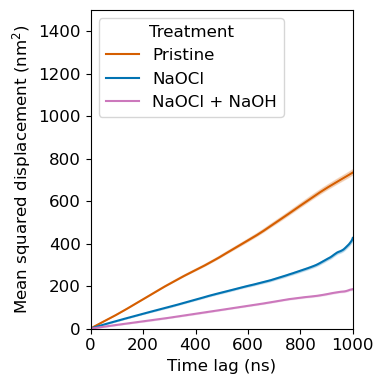

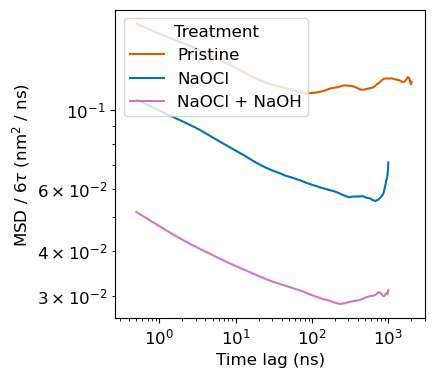

In [12]:
fig1, ax1 = plt.subplots(figsize=(col_width, row_height))
# plot MSDs for ions
for label in labels:
    path = paths[label]
    msds = pd.read_csv(path + 'ion_msd.csv')
    ax1.plot(msds['time'], msds['msd'], color=color_map[label], linestyle='-', label=label)
    ax1.fill_between(msds['time'], msds['lower_ci'], msds['upper_ci'], alpha=0.2, color=color_map[label])

ax1.set_xlabel('Time lag (ns)')
ax1.set_ylabel('Mean squared displacement (nm$^2$)')
ax1.set_xlim(0,1000)
ax1.set_ylim(0,1500)

ax1.legend(title='Treatment', loc='upper left')
fig1.tight_layout()

# plot MSDs, loglog
fig2, ax2 = plt.subplots(figsize=(col_width, row_height))
for label in labels:
    path = paths[label]
    msds = pd.read_csv(path + 'ion_msd.csv')
    ax2.loglog(msds['time'], msds['msd'] / (6*msds['time']), label=label, color=color_map[label])
    ax2.fill_between(np.log(msds['time']), np.log(msds['lower_ci'] / (6*msds['time'])), np.log(msds['upper_ci'] / (6*msds['time'])), alpha=0.2, color=color_map[label])

ax2.set_xlabel('Time lag (ns)')
ax2.set_ylabel(r'MSD / 6$\tau$ (nm$^2$ / ns) ')
ax2.legend(title='Treatment', loc='upper left')

### Water and ions

/Users/nate_schwindt/anaconda3/envs/mda/lib/python3.10/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)
/Users/nate_schwindt/anaconda3/envs/mda/lib/python3.10/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)
/Users/nate_schwindt/anaconda3/envs/mda/lib/python3.10/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)
/Users/nate_schwindt/anaconda3/envs/mda/lib/python3.10/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)
/Users/nate_schwindt/anaconda3/envs/mda/lib/python3.10/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, 

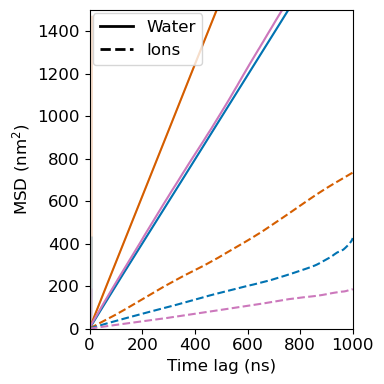

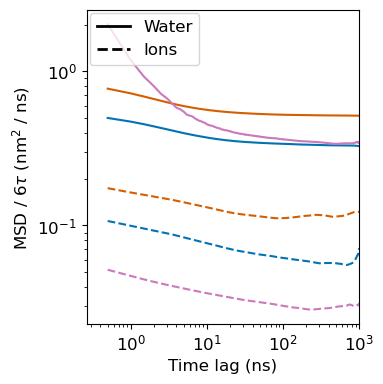

In [14]:
fig1, ax1 = plt.subplots(figsize=(col_width, row_height))
for label in labels:
    path = paths[label]
    msds = pd.read_csv(path + 'water_msd_unrestricted.csv')
    ax1.plot(msds['time'], msds['msd'], color=color_map[label])
    ax1.fill_between(msds['time'], msds['lower_ci'], msds['upper_ci'], alpha=0.2, color=color_map[label])

# plot MSDs for ions
for label in labels:
    path = paths[label]
    msds = pd.read_csv(path + 'ion_msd.csv')
    ax1.plot(msds['time'], msds['msd'], color=color_map[label], linestyle='--')
    ax1.fill_between(np.log(msds['time']), msds['lower_ci'], msds['upper_ci'], alpha=0.2, color=color_map[label])

ax1.set_xlabel('Time lag (ns)')
ax1.set_ylabel(r'MSD (nm$^2$)')
ax1.set_xlim(0,1000)
ax1.set_ylim(0,1500)

# Single legend: line styles for species in the top-right corner.
species_handles = [
    Line2D([0], [0], color='black', lw=2.0, linestyle='-', label='Water'),
    Line2D([0], [0], color='black', lw=2.0, linestyle='--', label='Ions'),
]
ax1.legend(
    handles=species_handles,
    loc='upper left',
    borderaxespad=0.2,
 )

fig1.tight_layout()
fig1.savefig(main_fig_output_path + 'msd_water_ion.png', dpi=dpi, bbox_inches='tight')
fig1.savefig(main_fig_output_path + 'msd_water_ion.pdf', bbox_inches='tight')

# loglog plot of water and ion MSDs together
fig2, ax2 = plt.subplots(figsize=(col_width, row_height))
for label in labels:
    path = paths[label]
    msds = pd.read_csv(path + 'water_msd_unrestricted.csv')
    ax2.loglog(msds['time'], msds['msd'] / (6*msds['time']), color=color_map[label])
    ax2.fill_between(np.log(msds['time']), np.log(msds['lower_ci'] / (6*msds['time'])), np.log(msds['upper_ci'] / (6*msds['time'])), alpha=0.2, color=color_map[label])

# plot MSDs for ions
for label in labels:
    path = paths[label]
    msds = pd.read_csv(path + 'ion_msd.csv')
    ax2.loglog(msds['time'], msds['msd'] / (6*msds['time']), color=color_map[label], linestyle='--')
    ax2.fill_between(np.log(msds['time']), np.log(msds['lower_ci'] / (6*msds['time'])), np.log(msds['upper_ci'] / (6*msds['time'])), alpha=0.2, color=color_map[label])

ax2.set_xlabel('Time lag (ns)')
ax2.set_ylabel(r'MSD / 6$\tau$ (nm$^2$ / ns) ')
ax2.set_xlim(0,1000)

# Single legend: line styles for species in the top-right corner.
species_handles = [
    Line2D([0], [0], color='black', lw=2.0, linestyle='-', label='Water'),
    Line2D([0], [0], color='black', lw=2.0, linestyle='--', label='Ions'),
]
ax2.legend(
    handles=species_handles,
    loc='upper left',
    borderaxespad=0.2,
 )

fig2.tight_layout()
fig2.savefig(si_fig_output_path + 'msd_water_ion_loglog.png', dpi=dpi, bbox_inches='tight')
fig2.savefig(si_fig_output_path + 'msd_water_ion_loglog.pdf', bbox_inches='tight')

#### Treatment and %time in membrane grid for water diffusion

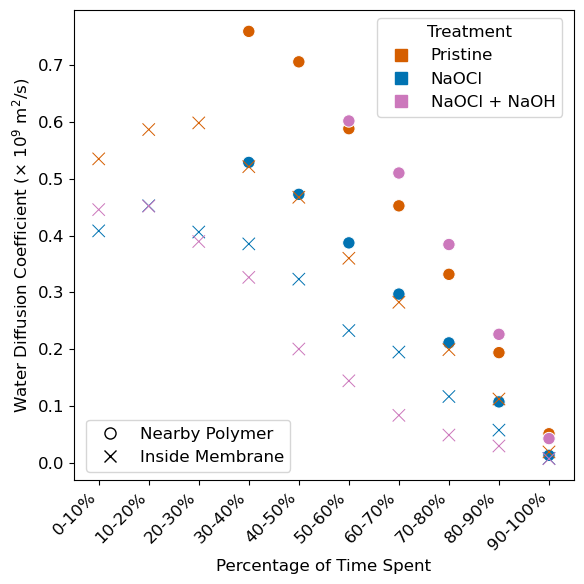

In [15]:
df = pd.DataFrame()
for label in labels:
    path = paths[label]
    tmp = pd.read_csv(path + 'diff_coeffs_by_water.csv')
    tmp['Treatment'] = label
    df = pd.concat([df, tmp], ignore_index=True)

# plot the diffusion coefficient as a function of percent time near polymer

order = ["Pristine", "NaOCl", "NaOCl + NaOH"]
inside_order = ["0-10%", "10-20%", "20-30%", "30-40%", "40-50%", "50-60%", "60-70%", "70-80%", "80-90%", "90-100%"]
inside_pos = {cat: i for i, cat in enumerate(inside_order)}

fig, ax = plt.subplots(figsize=(col_width*1.5, row_height*1.5))

# Nearby polymer series (circle markers)
tmp_near = df.pivot_table(
    columns="proximity_category",
    index="Treatment",
    values="diff_coeff",
    aggfunc="mean",
).T.melt(ignore_index=False, value_name='diff_coeff').reset_index()

tmp_near["Treatment"] = pd.Categorical(tmp_near["Treatment"], categories=order, ordered=True)
tmp_near["proximity_category"] = pd.Categorical(tmp_near["proximity_category"], categories=inside_order, ordered=True)
tmp_near = tmp_near.sort_values(["proximity_category", "Treatment"])
tmp_near["x_pos"] = tmp_near["proximity_category"].astype(str).map(inside_pos)

sns.scatterplot(
    data=tmp_near,
    x='x_pos',
    y='diff_coeff',
    hue='Treatment',
    hue_order=order,
    palette=color_map,
    s=80,
    marker='o',
    legend=False,
    ax=ax,
)

# Inside membrane series (x markers)
tmp_inside = df.pivot_table(
    columns="percent_time_inside_category",
    index="Treatment",
    values="diff_coeff",
    aggfunc="mean",
).T.melt(ignore_index=False, value_name='diff_coeff').reset_index()

tmp_inside["Treatment"] = pd.Categorical(tmp_inside["Treatment"], categories=order, ordered=True)
tmp_inside["percent_time_inside_category"] = pd.Categorical(tmp_inside["percent_time_inside_category"], categories=inside_order, ordered=True)
tmp_inside = tmp_inside.sort_values(["percent_time_inside_category", "Treatment"])
tmp_inside["x_pos"] = tmp_inside["percent_time_inside_category"].astype(str).map(inside_pos)

sns.scatterplot(
    data=tmp_inside,
    x='x_pos',
    y='diff_coeff',
    hue='Treatment',
    hue_order=order,
    palette=color_map,
    marker='x',
    s=80,
    legend=False,
    ax=ax,
)

# Bottom axis: proximity bins only
bottom_tick_pos = [inside_pos[c] for c in inside_order]
ax.set_xticks(bottom_tick_pos)
ax.set_xticklabels(inside_order, rotation=45, ha="right")
ax.set_xlabel('Percentage of Time Spent')
ax.set_ylabel(r'Water Diffusion Coefficient ($\times$ 10$^{9}$ m$^2$/s)')
ax.set_xlim(-0.5, len(inside_order) - 0.5)

# split legend: colors/treatments + markers/meaning
color_handles = [
    Line2D([0], [0], marker='s', linestyle='None', markersize=8,
           markerfacecolor=color_map[t], markeredgecolor=color_map[t], label=t)
    for t in order
]
shape_handles = [
    Line2D([0], [0], marker='o', linestyle='None', markersize=8,
           markerfacecolor='white', markeredgecolor='black', label='Nearby Polymer'),
    Line2D([0], [0], marker='x', linestyle='None', markersize=8,
           color='black', label='Inside Membrane'),
]

legend1 = ax.legend(handles=color_handles, title='Treatment', loc='upper left', bbox_to_anchor=(0.59, 1.0))
ax.add_artist(legend1)
ax.legend(handles=shape_handles, loc='lower right', bbox_to_anchor=(0.45, 0.0))

plt.tight_layout()
fig.savefig(si_fig_output_path + 'diff_coeff_by_proximity_and_inside.png', dpi=dpi, bbox_inches='tight')
fig.savefig(si_fig_output_path + 'diff_coeff_by_proximity_and_inside.pdf', bbox_inches='tight')

## Density

In [3]:
df = pd.DataFrame()

for label in labels:
    path = paths[label]
    dens = pd.read_csv(path + 'density.csv')
    dens['Treatment'] = label
    dens['thickness'] = membrane_bounds[label][3] - membrane_bounds[label][1] # Angstroms
    dens['volume'] = dens['thickness'] * dens['area'] # Angstroms^3
    df = pd.concat([df, dens], ignore_index=True)

### Mass density

For polymer mass density:
NaOCl percent change: 8.33%
NaOCl + NaOH percent change: 2.13%

For water mass density:
NaOCl percent change: -4.389%
NaOCl + NaOH percent change: -1.449%

For total mass density:
NaOCl percent change: 5.186%
NaOCl + NaOH percent change: 1.243%


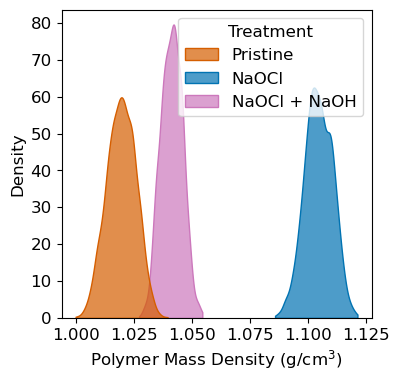

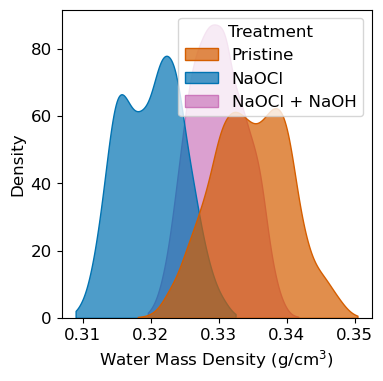

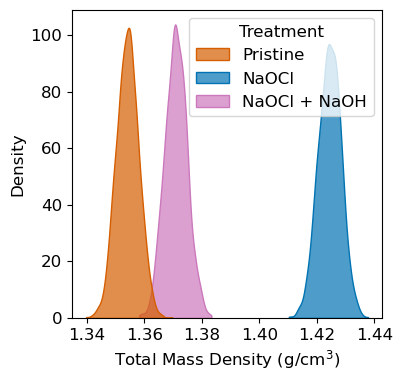

In [4]:
df['polymer_mass_density'] = df['polymer_mass'] / df['volume'] * (1 / 6.022e23) * (1e10 / 1e2)**3 # convert to g/cm^3
df['water_mass_density'] = df['water_mass'] / df['volume'] * (1 / 6.022e23) * (1e10 / 1e2)**3 # convert to g/cm^3
df['total_mass_density'] = (df['water_mass'] + df['polymer_mass']) / df['volume'] * (1 / 6.022e23) * (1e10 / 1e2)**3 # convert to g/cm^3

# polymer mass density KDE
fig, ax = plt.subplots(figsize=(col_width, row_height))
sns.kdeplot(data=df, x='polymer_mass_density', hue='Treatment', cut=0,
             fill=True, alpha=0.7, ax=ax, palette=color_map, common_norm=False)
ax.set_xlabel(r'Polymer Mass Density (g/cm$^3$)')
ax.set_ylabel('Density')

means = df.groupby('Treatment')['polymer_mass_density'].mean()

print('For polymer mass density:')
print(f"NaOCl percent change: {(means['NaOCl'] - means['Pristine']) / means['Pristine'] * 100:.2f}%")
print(f"NaOCl + NaOH percent change: {(means['NaOCl + NaOH'] - means['Pristine']) / means['Pristine'] * 100:.2f}%")

# water mass density KDE
fig, ax = plt.subplots(figsize=(col_width, row_height))
sns.kdeplot(data=df, x='water_mass_density', hue='Treatment', cut=0,
             fill=True, alpha=0.7, ax=ax, palette=color_map, common_norm=False)
ax.set_xlabel(r'Water Mass Density (g/cm$^3$)')
ax.set_ylabel('Density')

means = df.groupby('Treatment')['water_mass_density'].mean()

print('\nFor water mass density:')
print(f"NaOCl percent change: {(means['NaOCl'] - means['Pristine']) / means['Pristine'] * 100:.3f}%")
print(f"NaOCl + NaOH percent change: {(means['NaOCl + NaOH'] - means['Pristine']) / means['Pristine'] * 100:.3f}%")

# total mass density KDE
fig, ax = plt.subplots(figsize=(col_width, row_height))
sns.kdeplot(data=df, x='total_mass_density', hue='Treatment', cut=0,
             fill=True, alpha=0.7, ax=ax, palette=color_map, common_norm=False)
ax.set_xlabel(r'Total Mass Density (g/cm$^3$)')
ax.set_ylabel('Density')

means = df.groupby('Treatment')['total_mass_density'].mean()

print('\nFor total mass density:')
print(f"NaOCl percent change: {(means['NaOCl'] - means['Pristine']) / means['Pristine'] * 100:.3f}%")
print(f"NaOCl + NaOH percent change: {(means['NaOCl + NaOH'] - means['Pristine']) / means['Pristine'] * 100:.3f}%")

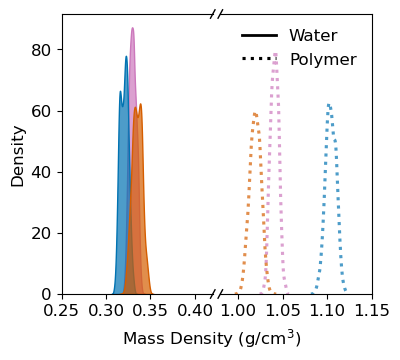

In [5]:
# Broken x-axis: [0.3, 0.4] and [0.95, 1.3]
fig, (ax_left, ax_right) = plt.subplots(
    1, 2, figsize=(col_width, row_height), sharey=True,
    gridspec_kw={'width_ratios': [1, 1], 'wspace': 0.05}
 )

for ax in (ax_left, ax_right):
    sns.kdeplot(
        data=df, x='polymer_mass_density', hue='Treatment',
        fill=False, alpha=0.7, ax=ax, palette=color_map, common_norm=False, linestyle='dotted', linewidth=2.25
    )
    sns.kdeplot(
        data=df, x='water_mass_density', hue='Treatment',
        fill=True, alpha=0.7, ax=ax, palette=color_map, common_norm=False
    )

# X tick labels every 0.05
ax_left.set_xticks(np.arange(0.25, 0.401, 0.05))
ax_right.set_xticks(np.arange(0.95, 1.151, 0.05))

# Set the two visible x ranges
ax_left.set_xlim(0.25, 0.42)
ax_right.set_xlim(0.98, 1.15)

# Axis labels: one centered x-label for combined axis
ax_left.set_xlabel('')
ax_right.set_xlabel('')
fig.supxlabel('Mass Density (g/cm$^3$)', y=0.04, fontsize=12)
ax_left.set_ylabel('Density')
ax_right.set_ylabel('')

# Remove all auto-generated treatment legends
if ax_left.get_legend() is not None:
    ax_left.get_legend().remove()
if ax_right.get_legend() is not None:
    ax_right.get_legend().remove()

# Species legend only
species_handles = [
    Line2D([0], [0], color='black', lw=2.0, linestyle='-', label='Water'),
    Line2D([0], [0], color='black', lw=2.25, linestyle='dotted', label='Polymer'),
]
ax_right.legend(handles=species_handles, loc='upper right', frameon=False)

# Hide shared boundary spines and remove right-side y ticks
ax_left.spines['right'].set_visible(False)
ax_right.spines['left'].set_visible(False)
ax_left.yaxis.tick_left()
ax_right.tick_params(axis='y', which='both', left=False, right=False, labelleft=False, labelright=False)

# Draw diagonal break marks
d = 0.015
kwargs = dict(transform=ax_left.transAxes, color='k', clip_on=False, linewidth=1.0)
ax_left.plot((1 - d, 1 + d), (-d, +d), **kwargs)
ax_left.plot((1 - d, 1 + d), (1 - d, 1 + d), **kwargs)
kwargs.update(transform=ax_right.transAxes)
ax_right.plot((-d, +d), (-d, +d), **kwargs)
ax_right.plot((-d, +d), (1 - d, 1 + d), **kwargs)

fig.subplots_adjust(wspace=0.05, bottom=0.18)
fig.savefig(main_fig_output_path + 'mass_density.png', dpi=dpi, bbox_inches='tight')
fig.savefig(main_fig_output_path + 'mass_density.pdf', bbox_inches='tight')

### Volume

NaOCl swelling: 5.20%
NaOCl + NaOH swelling: 3.12%


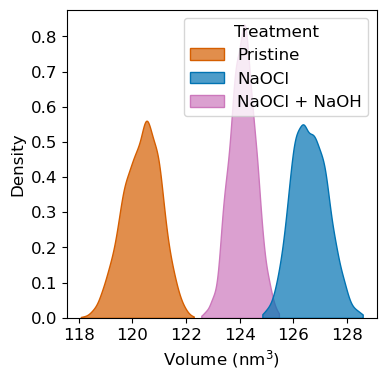

In [6]:
df['scaled_volume'] = df['volume'] * (1/10)**3 # scale to nm^3 for better readability

fig, ax = plt.subplots(figsize=(col_width, row_height))
sns.kdeplot(data=df, x='scaled_volume', hue='Treatment', cut=0,
             fill=True, alpha=0.7, ax=ax, palette=color_map, common_norm=False)
ax.set_xlabel(r'Volume (nm$^3$)')
ax.set_ylabel('Density')

means = df.groupby('Treatment')['scaled_volume'].mean()

print(f"NaOCl swelling: {(means['NaOCl'] - means['Pristine']) / means['Pristine'] * 100:.2f}%")
print(f"NaOCl + NaOH swelling: {(means['NaOCl + NaOH'] - means['Pristine']) / means['Pristine'] * 100:.2f}%")

fig.savefig(si_fig_output_path + 'membrane_volume_kde.png', dpi=dpi, bbox_inches='tight')
fig.savefig(si_fig_output_path + 'membrane_volume_kde.pdf', bbox_inches='tight')

### Number density

For polymer number density:
NaOCl percent change: -4.621%
NaOCl + NaOH percent change: 1.705%

For water number density:
NaOCl percent change: -4.321%
NaOCl + NaOH percent change: -1.336%

For total number density:
NaOCl percent change: -4.523%
NaOCl + NaOH percent change: 0.714%


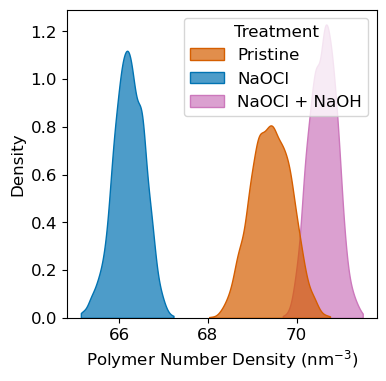

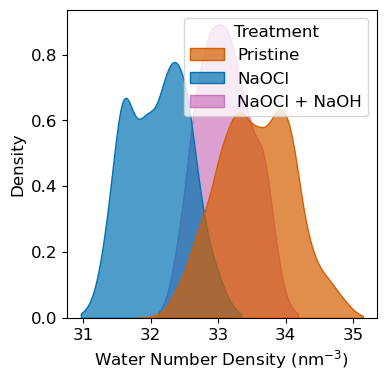

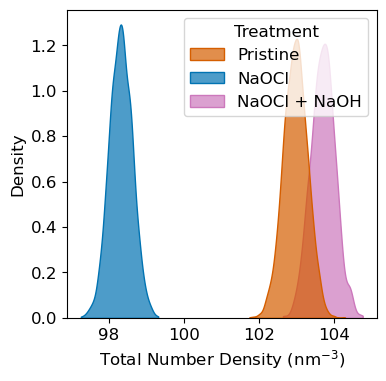

In [7]:
df['polymer_number_density'] = df['polymer_number'] / df['volume'] * (10/1)**3 # convert to number per nm^3
df['water_number_density'] = df['water_number'] / df['volume'] * (10/1)**3 # convert to number per nm^3
df['total_number_density'] = (df['water_number'] + df['polymer_number']) / df['volume'] * (10/1)**3 # convert to nm^3

# polymer number density KDE
fig, ax = plt.subplots(figsize=(col_width, row_height))
sns.kdeplot(data=df, x='polymer_number_density', hue='Treatment', cut=0,
             fill=True, alpha=0.7, ax=ax, palette=color_map, common_norm=False)
ax.set_xlabel(r'Polymer Number Density (nm$^{-3}$)')
ax.set_ylabel('Density')

means = df.groupby('Treatment')['polymer_number_density'].mean()

print("For polymer number density:")
print(f"NaOCl percent change: {(means['NaOCl'] - means['Pristine']) / means['Pristine'] * 100:.3f}%")
print(f"NaOCl + NaOH percent change: {(means['NaOCl + NaOH'] - means['Pristine']) / means['Pristine'] * 100:.3f}%")

# water number density KDE
fig, ax = plt.subplots(figsize=(col_width, row_height))
sns.kdeplot(data=df, x='water_number_density', hue='Treatment', cut=0,
             fill=True, alpha=0.7, ax=ax, palette=color_map, common_norm=False)
ax.set_xlabel(r'Water Number Density (nm$^{-3}$)')
ax.set_ylabel('Density')

means = df.groupby('Treatment')['water_number_density'].mean()

print("\nFor water number density:")
print(f"NaOCl percent change: {(means['NaOCl'] - means['Pristine']) / means['Pristine'] * 100:.3f}%")
print(f"NaOCl + NaOH percent change: {(means['NaOCl + NaOH'] - means['Pristine']) / means['Pristine'] * 100:.3f}%")

# total number density KDE
fig, ax = plt.subplots(figsize=(col_width, row_height))
sns.kdeplot(data=df, x='total_number_density', hue='Treatment', cut=0,
             fill=True, alpha=0.7, ax=ax, palette=color_map, common_norm=False)
ax.set_xlabel(r'Total Number Density (nm$^{-3}$)')
ax.set_ylabel('Density')

means = df.groupby('Treatment')['total_number_density'].mean()

print("\nFor total number density:")
print(f"NaOCl percent change: {(means['NaOCl'] - means['Pristine']) / means['Pristine'] * 100:.3f}%")
print(f"NaOCl + NaOH percent change: {(means['NaOCl + NaOH'] - means['Pristine']) / means['Pristine'] * 100:.3f}%")

NaOCl percent change: 0.324%
NaOCl + NaOH percent change: -1.470%


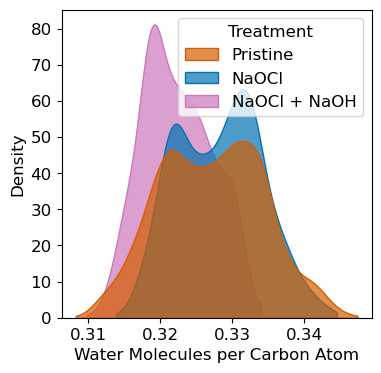

In [8]:
df['water_per_carbon'] = df['water_number'] / 3 / df['C_number'] # 3 atoms per water

fig, ax = plt.subplots(figsize=(col_width, row_height))
sns.kdeplot(data=df, x='water_per_carbon', hue='Treatment', cut=0,
             fill=True, alpha=0.7, ax=ax, palette=color_map, common_norm=False)
ax.set_xlabel(r'Water Molecules per Carbon Atom')
ax.set_ylabel('Density')

means = df.groupby('Treatment')['water_per_carbon'].mean()

print(f"NaOCl percent change: {(means['NaOCl'] - means['Pristine']) / means['Pristine'] * 100:.3f}%")
print(f"NaOCl + NaOH percent change: {(means['NaOCl + NaOH'] - means['Pristine']) / means['Pristine'] * 100:.3f}%")

#### Density profiles

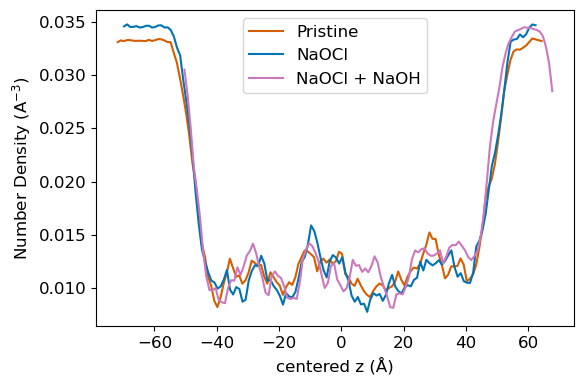

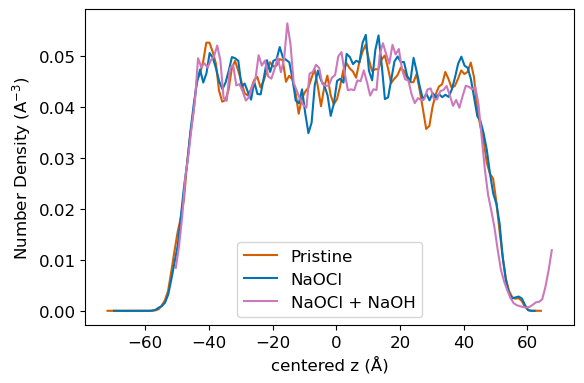

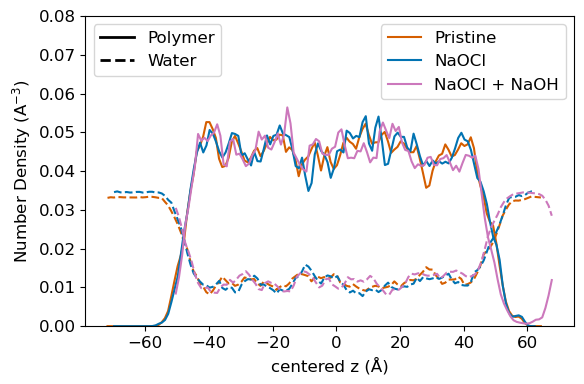

In [10]:
fig1, ax1 = plt.subplots(figsize=(col_width*1.5, row_height))
fig2, ax2 = plt.subplots(figsize=(col_width*1.5, row_height))
fig3, ax3 = plt.subplots(figsize=(col_width*1.5, row_height))

i = 0
for label in labels:
    path = paths[label]
    dens = pd.read_csv(path + 'density_profiles_heavy_atoms.csv')
    dens['system'] = label

    ax1.plot(dens['z'] - membrane_bounds[label][2], dens['water_density_profile'], label=label, color=color_map[label])
    ax2.plot(dens['z'] - membrane_bounds[label][2], dens['polymer_density_profile'], label=label, color=color_map[label])
    ax3.plot(dens['z'] - membrane_bounds[label][2], dens['polymer_density_profile'], label=label, color=color_map[label])
    ax3.plot(dens['z'] - membrane_bounds[label][2], dens['water_density_profile'], label=label, color=color_map[label], ls='--')
    i += 1

    # for b in range(5):
    #     ax3.axvline(membrane_bounds[label][b] - membrane_bounds[label][2], color=color_map[label], linestyle=':', alpha=0.2)

    # ax3.axvline(membrane_bounds[label][0] - membrane_bounds[label][2] - 10, color='black', linestyle=':', alpha=0.2)
    # ax3.axvline(membrane_bounds[label][-1] - membrane_bounds[label][2] + 10, color='black', linestyle=':', alpha=0.2)

ax1.set_xlabel('centered z (Å)')
ax1.set_ylabel('Number Density (A$^{-3}$)')
ax1.legend()
fig1.tight_layout()

ax2.set_xlabel('centered z (Å)')
ax2.set_ylabel('Number Density (A$^{-3}$)')
ax2.legend()
fig2.tight_layout()

ax3.set_xlabel('centered z (Å)')
ax3.set_ylabel('Number Density (A$^{-3}$)')
ax3.set_ylim(0, 0.08)

handles, labels_ = ax3.get_legend_handles_labels()
unique = {}
for handle, label in zip(handles, labels_):
    if label not in unique:
        unique[label] = handle
color_legend = ax3.legend(
    unique.values(),
    unique.keys(),
    loc='upper right',
    frameon=True,
)
ax3.add_artist(color_legend)

style_handles = [
    Line2D([0], [0], color='black', lw=2.0, linestyle='-', label='Polymer'),
    Line2D([0], [0], color='black', lw=2.0, linestyle='--', label='Water'),
]
ax3.legend(
    handles=style_handles,
    loc='upper left',
    ncol=1,
    frameon=True,
)

fig3.tight_layout()
fig3.savefig(si_fig_output_path + 'number_density_profiles.png', dpi=dpi, bbox_inches='tight')
fig3.savefig(si_fig_output_path + 'number_density_profiles.pdf', bbox_inches='tight')

## Water dwell events in the membrane

In [23]:
df = pd.DataFrame()

for label in labels:
    path = paths[label]
    tmp = pd.read_csv(path + 'membrane_events_df_filtered.csv')
    tmp['Treatment'] = label
    print(f"{label}: {tmp.shape[0]} events")
    df = pd.concat([df, tmp], ignore_index=True)

df

Pristine: 9232 events
NaOCl: 8386 events
NaOCl + NaOH: 8637 events


,mol,start_frame,end_frame,dwell_time,entry_region,exit_region,periodic_jump,direction,path,Treatment
0,1,1427,1789,363,A,A,False,A_to_A,return,Pristine
1,3,453,935,483,B,B,False,B_to_B,return,Pristine
2,4,577,809,233,B,B,False,B_to_B,return,Pristine
3,6,1231,1415,185,A,B,True,A_to_B,return,Pristine
4,6,1844,2000,157,A,NaN,False,A_to_inside,entry,Pristine
...,...,...,...,...,...,...,...,...,...,...
26250,4998,0,42,43,NaN,A,False,inside_to_A,exit,NaOCl + NaOH
26251,4998,1799,2000,202,A,NaN,False,A_to_inside,entry,NaOCl + NaOH
26252,4999,0,25,26,NaN,A,False,inside_to_A,exit,NaOCl + NaOH
26253,5000,0,1575,1576,NaN,A,False,inside_to_A,exit,NaOCl + NaOH


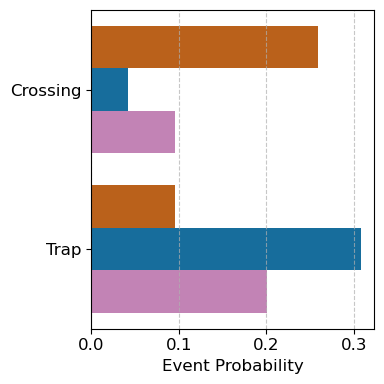

In [24]:
desired_path_order = ['crossing', 'trap']
observed_paths = df['path'].dropna().unique().tolist()
path_order = [path for path in desired_path_order if path in observed_paths]

treatment_order = [label for label in labels if label in df['Treatment'].dropna().unique()]
plot_df = df[df['path'].isin(path_order) & df['Treatment'].isin(treatment_order)].copy()

# Display labels with initial capitals while keeping source values unchanged.
path_label_map = {p: p.capitalize() for p in path_order}
path_order_display = [path_label_map[p] for p in path_order]
plot_df['path_display'] = plot_df['path'].map(path_label_map)

total_events = len(plot_df)
prob_df = (
    plot_df.groupby(['path_display', 'Treatment'])
    .size()
    .rename('count')
    .reset_index()
    .assign(probability=lambda d: d['count'] / total_events)
    .drop(columns='count')
)

# Keep consistent plotting order for both panels.
prob_df['path_display'] = pd.Categorical(prob_df['path_display'], categories=path_order_display, ordered=True)
prob_df = prob_df.sort_values(['path_display', 'Treatment'])

fig, ax = plt.subplots(1, 1, figsize=(4, 4))

# Left panel: probability by (path, treatment).
sns.barplot(
    data=prob_df,
    x='probability',
    y='path_display',
    hue='Treatment',
    order=path_order_display,
    hue_order=treatment_order,
    palette=color_map,
    estimator=sum,
    errorbar=None,
    ax=ax,
 )
ax.set_xlabel('Event Probability')
ax.set_ylabel('')
ax.grid(axis='x', linestyle='--', alpha=0.7)


# Keep a single legend.
handles, labels_legend = ax.get_legend_handles_labels()
if ax.legend_ is not None:
    ax.legend_.remove()

fig.tight_layout()
fig.savefig(main_fig_output_path + 'membrane_event_probabilities.png', dpi=dpi, bbox_inches='tight')
fig.savefig(main_fig_output_path + 'membrane_event_probabilities.pdf', bbox_inches='tight')

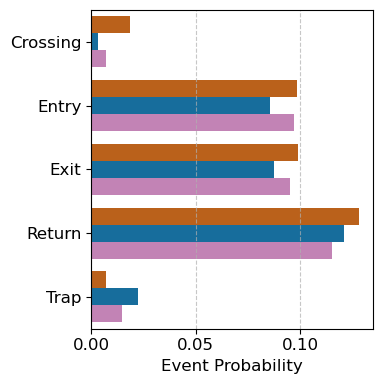

In [25]:
desired_path_order = ['crossing', 'entry', 'exit', 'return', 'trap']
observed_paths = df['path'].dropna().unique().tolist()
path_order = [path for path in desired_path_order if path in observed_paths]
path_order += [path for path in observed_paths if path not in path_order]

treatment_order = [label for label in labels if label in df['Treatment'].dropna().unique()]
plot_df = df[df['path'].isin(path_order) & df['Treatment'].isin(treatment_order)].copy()

# Display labels with initial capitals while keeping source values unchanged.
path_label_map = {p: p.capitalize() for p in path_order}
path_order_display = [path_label_map[p] for p in path_order]
plot_df['path_display'] = plot_df['path'].map(path_label_map)

total_events = len(plot_df)
prob_df = (
    plot_df.groupby(['path_display', 'Treatment'])
    .size()
    .rename('count')
    .reset_index()
    .assign(probability=lambda d: d['count'] / total_events)
    .drop(columns='count')
)

# Keep consistent plotting order for both panels.
prob_df['path_display'] = pd.Categorical(prob_df['path_display'], categories=path_order_display, ordered=True)
prob_df = prob_df.sort_values(['path_display', 'Treatment'])

fig, ax = plt.subplots(1, 1, figsize=(4, 4))

# Left panel: probability by (path, treatment).
sns.barplot(
    data=prob_df,
    x='probability',
    y='path_display',
    hue='Treatment',
    order=path_order_display,
    hue_order=treatment_order,
    palette=color_map,
    estimator=sum,
    errorbar=None,
    ax=ax,
 )
ax.set_xlabel('Event Probability')
ax.set_ylabel('')
ax.grid(axis='x', linestyle='--', alpha=0.7)


# Keep a single legend.
handles, labels_legend = ax.get_legend_handles_labels()
if ax.legend_ is not None:
    ax.legend_.remove()

fig.tight_layout()
fig.savefig(si_fig_output_path + 'event_probabilities_detailed.png', dpi=dpi, bbox_inches='tight')
fig.savefig(si_fig_output_path + 'event_probabilities_detailed.pdf', bbox_inches='tight')

## RDFs

In [16]:
def plot_rdf(df : pd.DataFrame, y: str, label: str = None, x: str = 'r_A', ax : plt.Axes = None, scale: bool = False) -> None:
    '''
    Parameters
    ----------
    df : pd.DataFrame
        DataFrame containing the RDF data.
    y : str
        Column name for the y-axis (typically g(r) values).
    label : str, optional
        Label for the plot (used in the legend).
    x : str, optional
        Column name for the x-axis (typically distance).
    ax : plt.Axes, optional
        The axes object to plot on.
    scale : bool, optional
        Rescale the RDF by the value at large r
    '''

    if ax is None:
        plt.figure(figsize=(4, 4))
    else:
        plt.sca(ax)

    if label is None:
        label = y.removeprefix('rdf_')
        color = None
    else:
        color = color_map[label]

    if scale:    
        plt.plot(df[x], df[y] / df[y].iloc[-1], label=label, color=color)
    else:
        plt.plot(df[x], df[y], label=label, color=color)
    plt.xlabel('r (Å)', fontsize=12)
    plt.ylabel('g(r)', fontsize=12)
    plt.xlim(2,6)
    plt.legend()
    plt.grid(alpha=0.25)

    return ax


In [4]:
df = pd.DataFrame()

for label in labels:
    path = paths[label]
    tmp = pd.read_csv(path + 'rdfs.csv')
    tmp['Treatment'] = label
    df = pd.concat([df, tmp], ignore_index=True)

df

,r_A,rdf_cations_waters,count_cations_waters,rdf_cations_anions,count_cations_anions,rdf_cations_cations,count_cations_cations,rdf_cations_coo_o,count_cations_coo_o,rdf_cations_nh2,...,count_ha_waters_polymer,rdf_ha_waters_ca,count_ha_waters_ca,rdf_ha_waters_amide_o,count_ha_waters_amide_o,rdf_ha_waters_coo_o,count_ha_waters_coo_o,rdf_ha_ortho_para_polymer,count_ha_ortho_para_polymer,Treatment
0,0.025,0.000000,0.0,0.000000,0.0,0.000000,0.0,0.000000,0.0,0.000000,...,0.0,0.000000,0.0,0.000000,0.0,0.000000,0.0,0.000000,0.0,Pristine
1,0.075,0.000000,0.0,0.000000,0.0,0.000000,0.0,0.000000,0.0,0.000000,...,0.0,0.000000,0.0,0.000000,0.0,0.000000,0.0,0.000000,0.0,Pristine
2,0.125,0.000000,0.0,0.000000,0.0,0.000000,0.0,0.000000,0.0,0.000000,...,0.0,0.000000,0.0,0.000000,0.0,0.000000,0.0,0.000000,0.0,Pristine
3,0.175,0.000000,0.0,0.000000,0.0,0.000000,0.0,0.000000,0.0,0.000000,...,0.0,0.000000,0.0,0.000000,0.0,0.000000,0.0,0.000000,0.0,Pristine
4,0.225,0.000000,0.0,0.000000,0.0,0.000000,0.0,0.000000,0.0,0.000000,...,0.0,0.000000,0.0,0.000000,0.0,0.000000,0.0,0.000000,0.0,Pristine
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
595,9.775,1.089575,176773.0,1.333600,476.0,1.402872,7784.0,1.277277,13221.0,0.905374,...,6994588.0,1.083669,4261580.0,1.075062,669601.0,0.980453,170284.0,1.175096,3510955.0,NaOCl + NaOH
596,9.825,1.091851,178959.0,1.231317,444.0,1.399690,7846.0,1.266413,13243.0,0.912288,...,7066920.0,1.084267,4307665.0,1.069402,672907.0,0.980028,171956.0,1.177505,3554237.0,NaOCl + NaOH
597,9.875,1.093022,180979.0,1.345160,490.0,1.366480,7738.0,1.266874,13383.0,0.924613,...,7149791.0,1.085904,4358193.0,1.068561,679239.0,0.980250,173750.0,1.181145,3601605.0,NaOCl + NaOH
598,9.925,1.094658,183090.0,1.337077,492.0,1.373026,7854.0,1.252080,13361.0,0.931522,...,7220005.0,1.086118,4403303.0,1.066856,685040.0,0.981345,175710.0,1.181702,3639882.0,NaOCl + NaOH


In [5]:
names = [('cations', 'waters'), ('cations', 'anions'), ('cations', 'cations'), ('cations', 'coo_o'), ('cations', 'nh2'), ('cations', 'amide_o'), ('cations', 'amide_n'), ('cations', 'cl'), ('cations', 'ca'), ('cations', 'ha_ortho_para'),
         ('anions', 'waters'),  ('anions', 'anions'), ('anions', 'coo_o'), ('anions', 'nh2'), ('anions', 'amide_o'), ('anions', 'amide_n'), ('anions', 'cl'), ('anions', 'ca'), ('anions', 'ha_ortho_para'),
         ('coo_o', 'waters'), ('coo_o', 'coo_o'), ('coo_o', 'nh2'), ('coo_o', 'amide_o'), ('coo_o', 'amide_n'), ('coo_o', 'cl'), ('coo_o', 'ca'), ('coo_o', 'ha_ortho_para'),
         ('nh2', 'waters'), ('nh2', 'nh2'), ('nh2', 'amide_o'), ('nh2', 'amide_n'), ('nh2', 'cl'), ('nh2', 'ca'), ('nh2', 'ha_ortho_para'),
         ('amide_o', 'waters'), ('amide_o', 'amide_o'), ('amide_o', 'amide_n'), ('amide_o', 'cl'), ('amide_o', 'ca'), ('amide_o', 'ha_ortho_para'),
         ('amide_n', 'waters'), ('amide_n', 'amide_n'), ('amide_n', 'cl'), ('amide_n', 'ca'), ('amide_n', 'ha_ortho_para'),
         ('cl', 'waters'), ('cl', 'cl'), ('cl', 'ca'), ('cl', 'ha_ortho_para'),
         ('ca', 'waters'), ('ca', 'ca'), ('ca', 'ha_ortho_para'),
         ('ha_ortho_para', 'waters'), ('ha_ortho_para', 'ha_ortho_para'),
         ('waters', 'waters')]

Text(0.5, 1.0, 'scaled COO$^-$ - H$_2$O')

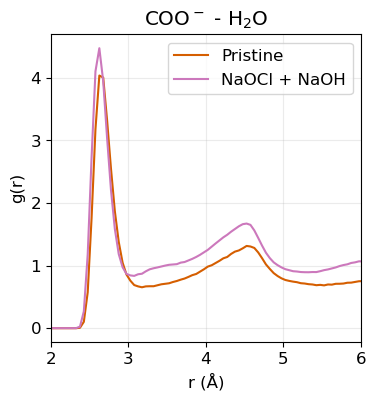

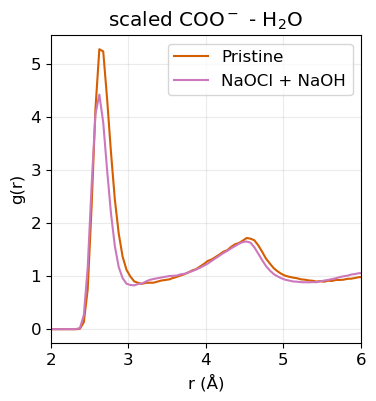

In [22]:
name = ('coo_o', 'waters')

fig, ax = plt.subplots(figsize=(col_width, row_height))

label = 'Pristine'
plot_rdf(df[df['Treatment'] == label], y=f'rdf_{name[0]}_{name[1]}', label=label, x='r_A', ax=ax)

label = 'NaOCl + NaOH'
plot_rdf(df[df['Treatment'] == label], y=f'rdf_{name[0]}_{name[1]}', label=label, x='r_A', ax=ax)

plt.title('COO$^-$ - H$_2$O')

# scaled
fig, ax = plt.subplots(figsize=(col_width, row_height))

label = 'Pristine'
plot_rdf(df[df['Treatment'] == label], y=f'rdf_{name[0]}_{name[1]}', label=label, x='r_A', ax=ax, scale=True)

label = 'NaOCl + NaOH'
plot_rdf(df[df['Treatment'] == label], y=f'rdf_{name[0]}_{name[1]}', label=label, x='r_A', ax=ax, scale=True)

plt.title('scaled COO$^-$ - H$_2$O')

(2.0, 10.0)

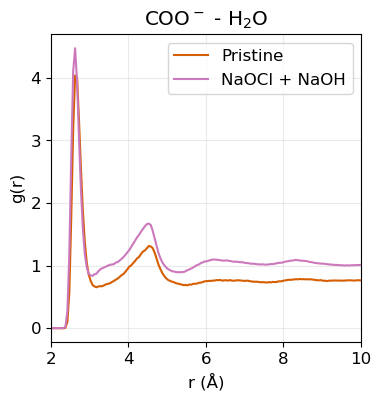

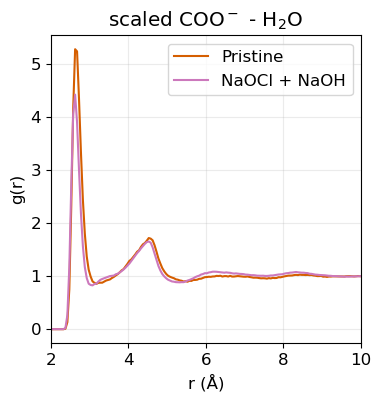

In [23]:
name = ('coo_o', 'waters')

fig, ax = plt.subplots(figsize=(col_width, row_height))

label = 'Pristine'
plot_rdf(df[df['Treatment'] == label], y=f'rdf_{name[0]}_{name[1]}', label=label, x='r_A', ax=ax)

label = 'NaOCl + NaOH'
plot_rdf(df[df['Treatment'] == label], y=f'rdf_{name[0]}_{name[1]}', label=label, x='r_A', ax=ax)

plt.title('COO$^-$ - H$_2$O')
plt.xlim(2,10)

# scaled
fig, ax = plt.subplots(figsize=(col_width, row_height))

label = 'Pristine'
plot_rdf(df[df['Treatment'] == label], y=f'rdf_{name[0]}_{name[1]}', label=label, x='r_A', ax=ax, scale=True)

label = 'NaOCl + NaOH'
plot_rdf(df[df['Treatment'] == label], y=f'rdf_{name[0]}_{name[1]}', label=label, x='r_A', ax=ax, scale=True)

plt.title('scaled COO$^-$ - H$_2$O')
plt.xlim(2,10)

Text(0.5, 1.0, 'scaled ortho-para position - H$_2$O')

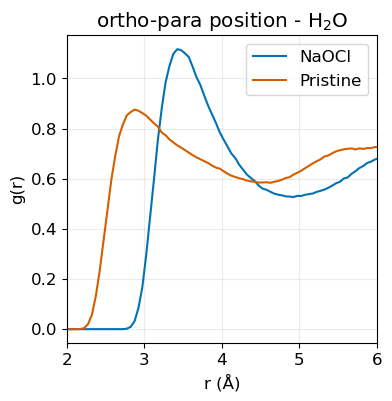

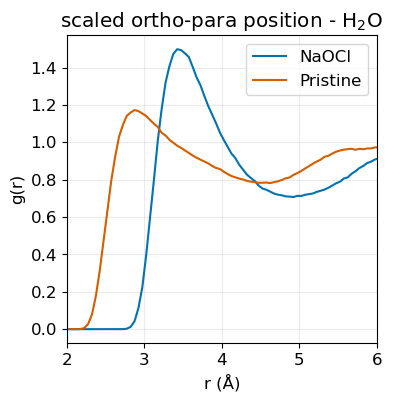

In [24]:
fig, ax = plt.subplots(figsize=(col_width, row_height))

name = ('cl', 'waters')
label = 'NaOCl'
plot_rdf(df[df['Treatment'] == label], y=f'rdf_{name[0]}_{name[1]}', label=label, x='r_A', ax=ax)

name = ('ha_ortho_para', 'waters')
label = 'Pristine'
plot_rdf(df[df['Treatment'] == label], y=f'rdf_{name[0]}_{name[1]}', label=label, x='r_A', ax=ax)

plt.title('ortho-para position - H$_2$O')

# scaled
fig, ax = plt.subplots(figsize=(col_width, row_height))

name = ('cl', 'waters')
label = 'NaOCl'
plot_rdf(df[df['Treatment'] == label], y=f'rdf_{name[0]}_{name[1]}', label=label, x='r_A', ax=ax, scale=True)

name = ('ha_ortho_para', 'waters')
label = 'Pristine'
plot_rdf(df[df['Treatment'] == label], y=f'rdf_{name[0]}_{name[1]}', label=label, x='r_A', ax=ax, scale=True)

plt.title('scaled ortho-para position - H$_2$O')

(2.0, 10.0)

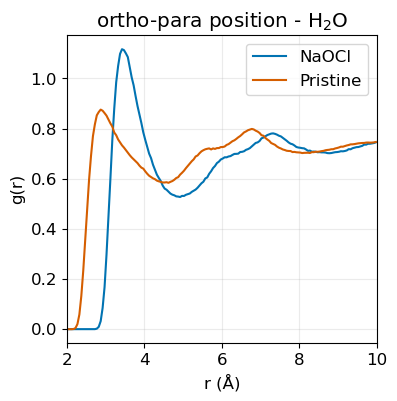

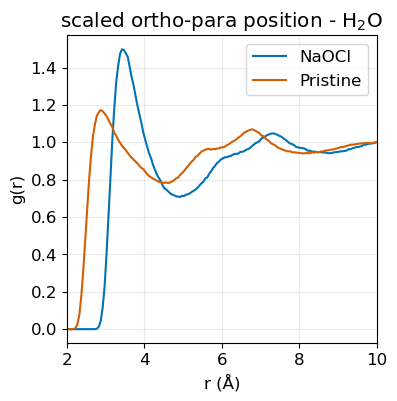

In [25]:
fig, ax = plt.subplots(figsize=(col_width, row_height))

name = ('cl', 'waters')
label = 'NaOCl'
plot_rdf(df[df['Treatment'] == label], y=f'rdf_{name[0]}_{name[1]}', label=label, x='r_A', ax=ax)

name = ('ha_ortho_para', 'waters')
label = 'Pristine'
plot_rdf(df[df['Treatment'] == label], y=f'rdf_{name[0]}_{name[1]}', label=label, x='r_A', ax=ax)

plt.title('ortho-para position - H$_2$O')
plt.xlim(2,10)

# scaled
fig, ax = plt.subplots(figsize=(col_width, row_height))

name = ('cl', 'waters')
label = 'NaOCl'
plot_rdf(df[df['Treatment'] == label], y=f'rdf_{name[0]}_{name[1]}', label=label, x='r_A', ax=ax, scale=True)

name = ('ha_ortho_para', 'waters')
label = 'Pristine'
plot_rdf(df[df['Treatment'] == label], y=f'rdf_{name[0]}_{name[1]}', label=label, x='r_A', ax=ax, scale=True)

plt.title('scaled ortho-para position - H$_2$O')
plt.xlim(2,10)